# 07 · Disruptions, port traffic and public holidays

**Questions:** What disruptions occur, how severe and how long are they, and how do they affect port operations? Do
disruptions known at departure, recent traffic deviations, or nearby public holidays distinguish risk classes?

Timing matters for every variable here:
* a disruption that has **already started** at the prediction cutoff is knowable; its **end time and total duration are
  not** (they are only known once it ends);
* daily traffic for day *D* is complete only after *D* ends, so the last usable day is *D − 1*;
* public holidays are published in advance, so holiday features are safe even for future dates.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss

from cargomind_eda import io, stats, features, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS

P.setup()
T = io.load_all()
dis, tel, traffic, hol, meta = T["disruption_events"], T["port_hourly_telemetry"], T["port_traffic_history"], T["public_holidays"], T["port_metadata"]
dis["duration_h"] = (dis.event_end - dis.event_start).dt.total_seconds() / 3600
f = features.build_shipment_features(lag_hours=1, tables=T)
sea = f[f.shipping_mode == "sea"].copy()

## G1. Disruption events: type, severity, duration, capacity impact

In [2]:
display(pd.crosstab(dis.event_type, dis.severity, margins=True))
display(dis.groupby("event_type").agg(n=("event_id", "size"), median_duration_h=("duration_h", "median"), max_duration_h=("duration_h", "max"),
                                     median_capacity_pct=("affected_capacity_pct", "median")).round(1))
print("events whose end time was reconstructed during cleaning (notebook 01): EVT00007, EVT00022, EVT00052")
print("event_end at or after the last telemetry hour (right-censored):", (dis.event_end >= tel.ts_hour.max()).sum())
print("affected_capacity_pct = 85.0 exactly (cap?):", (dis.affected_capacity_pct == 85).sum())

severity,low,medium,high,All
event_type,,,,
congestion,0,9,0,9
cyber,0,1,0,1
equipment_failure,5,6,0,11
strike,0,1,6,7
weather,0,4,23,27
All,5,21,29,55


,n,median_duration_h,max_duration_h,median_capacity_pct
event_type,,,,
congestion,9,61,97,38.1
cyber,1,16,16,38.3
equipment_failure,11,15,27,32.8
strike,7,56,86,55.9
weather,27,15,30,71.6


events whose end time was reconstructed during cleaning (notebook 01): EVT00007, EVT00022, EVT00052
event_end at or after the last telemetry hour (right-censored): 3
affected_capacity_pct = 85.0 exactly (cap?): 7


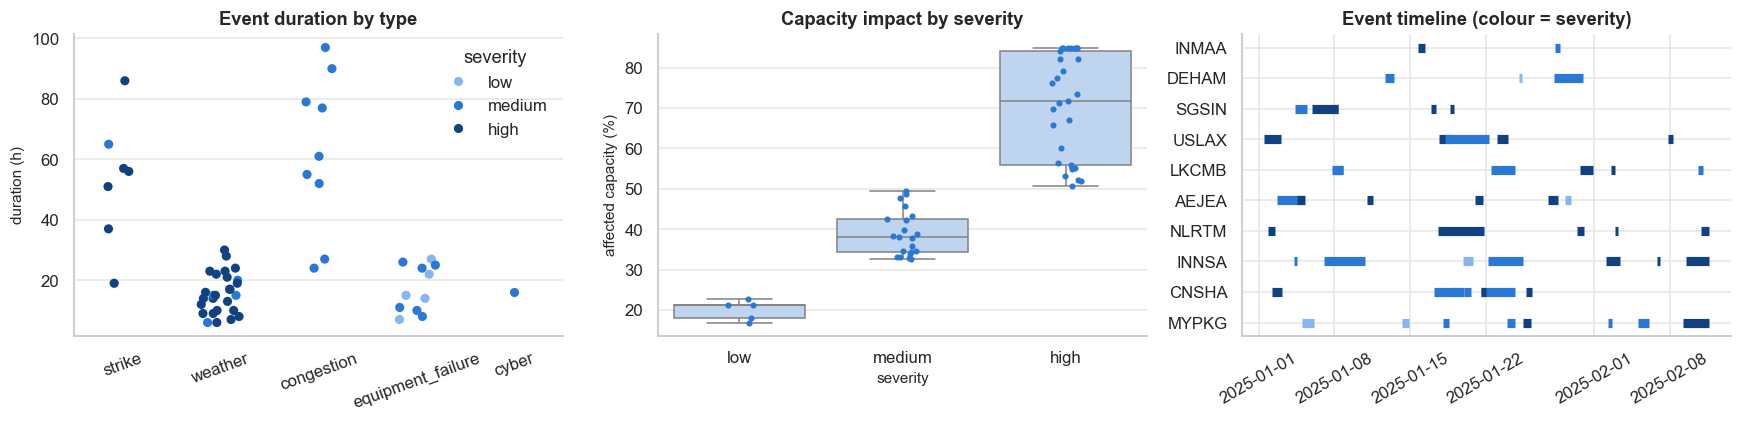

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.stripplot(data=dis, x="event_type", y="duration_h", hue="severity", palette={"low": "#86b6ef", "medium": "#2a78d6", "high": "#104281"}, ax=axes[0], size=6, jitter=0.2)
axes[0].set_ylabel("duration (h)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_title("Event duration by type")
sns.boxplot(data=dis, x="severity", y="affected_capacity_pct", ax=axes[1], color="#b7d3f6", linewidth=1)
sns.stripplot(data=dis, x="severity", y="affected_capacity_pct", ax=axes[1], color="#2a78d6", size=4)
axes[1].set_ylabel("affected capacity (%)")
axes[1].set_title("Capacity impact by severity")
ports_order = dis.port_id.value_counts().index
for i, p in enumerate(ports_order):
    for _, e in dis[dis.port_id == p].iterrows():
        axes[2].plot([e.event_start, e.event_end], [i, i], lw=6, solid_capstyle="butt",
                     color={"low": "#86b6ef", "medium": "#2a78d6", "high": "#104281"}[e.severity])
axes[2].set_yticks(range(len(ports_order)), ports_order)
axes[2].set_title("Event timeline (colour = severity)")
axes[2].tick_params(axis="x", rotation=30)
P.save(fig, "07_disruption_overview")

Severity is consistent with `affected_capacity_pct` (low ≈ 17–23 %, medium ≈ 32–50 %, high ≈ 50–85 %). The value 85.0
appears repeatedly, which suggests the impact measure is capped at 85 %. That is consistent with clipping, but cannot be
confirmed from the data. Weather events are short (median ~15 h); strikes and congestion last longer.

## G2. Disruptions known at departure vs delay class

In [4]:
for c in ["dis_o_active_any", "dis_d_active_any", "dis_h_active_any"]:
    print(f"{c}: share of sea shipments = {sea[c].mean()*100:.1f}%")
sea["origin_event"] = np.select(
    [sea.dis_o_active_any == 0, sea.dis_o_active_max_sev == 1, sea.dis_o_active_max_sev == 2, sea.dis_o_active_max_sev == 3],
    ["none", "low", "medium", "high"], default="none")
r = stats.class_rates(sea, "origin_event").reindex(["none", "low", "medium", "high"])
display(r)
print(stats.chi2_vs_target(sea, "origin_event"))

dis_o_active_any: share of sea shipments = 15.3%
dis_d_active_any: share of sea shipments = 15.3%
dis_h_active_any: share of sea shipments = 14.8%


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
origin_event,,,,,,,
none,7916,58.6,31,10.4,41.4,40.3,42.4
low,63,71.4,17.5,11.1,28.6,18.9,40.7
medium,713,28.8,47.7,23.6,71.2,67.8,74.4
high,655,4.1,22.7,73.1,95.9,94.1,97.2


{'feature': 'origin_event', 'levels': 4, 'chi2': np.float64(2045.0697258614757), 'dof': 6, 'p_value': np.float64(0.0), 'cramers_v': np.float64(0.3303020919409447), 'min_expected': np.float64(9.95517278271103), 'pct_cells_expected_lt5': np.float64(0.0)}


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
origin_event_type,,,,,,,
congestion,520,23.1,44,32.9,76.9,73.1,80.3
cyber,14,42.9,57.1,0,57.1,32.6,78.6
equipment_failure,174,52.3,36.8,10.9,47.7,40.4,55.1
none,7916,58.6,31,10.4,41.4,40.3,42.4
strike,349,14.6,45,40.4,85.4,81.3,88.7
weather,374,2.4,11.2,86.4,97.6,95.5,98.7


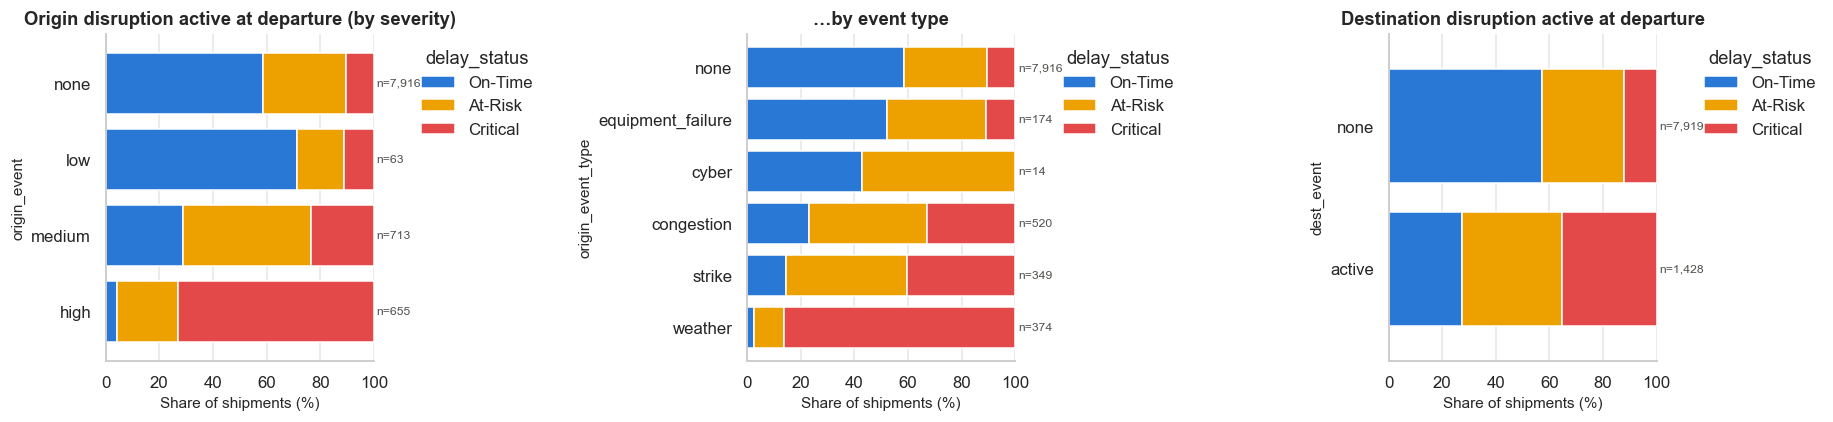

In [5]:
types = ["weather", "strike", "congestion", "equipment_failure", "cyber"]
sea["origin_event_type"] = "none"
for t in types:
    sea.loc[sea[f"dis_o_active_{t}"] > 0, "origin_event_type"] = t
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
P.stacked_class_bar(sea, "origin_event", ax=axes[0], order=["none", "low", "medium", "high"], title="Origin disruption active at departure (by severity)")
P.stacked_class_bar(sea, "origin_event_type", ax=axes[1], title="…by event type")
sea["dest_event"] = np.where(sea.dis_d_active_any > 0, "active", "none")
P.stacked_class_bar(sea, "dest_event", ax=axes[2], order=["none", "active"], title="Destination disruption active at departure")
P.save(fig, "07_disruption_at_departure_by_class")
display(stats.class_rates(sea, "origin_event_type"))

### Disruption duration: what is knowable at departure?
For shipments departing during an active origin event: hours **already elapsed** (knowable) vs hours **remaining**
(requires `event_end` — not knowable while the event is ongoing).

shipments departing during an active origin event: 1431
  Spearman(dis_o_active_hours_elapsed, delay) = -0.251
  Spearman(LEAK_dis_o_active_hours_remaining, delay) = -0.120
  Spearman(dis_o_active_capacity_pct, delay) = +0.603


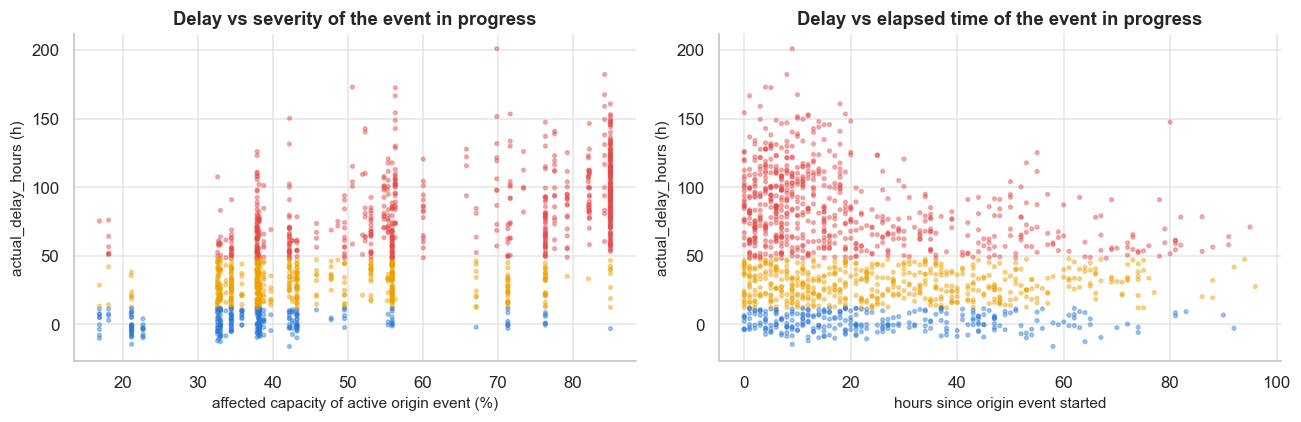

In [6]:
act = sea[sea.dis_o_active_any == 1]
print(f"shipments departing during an active origin event: {len(act)}")
for c in ["dis_o_active_hours_elapsed", "LEAK_dis_o_active_hours_remaining", "dis_o_active_capacity_pct"]:
    print(f"  Spearman({c}, delay) = {ss.spearmanr(act[c], act.actual_delay_hours)[0]:+.3f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c, lab in [(axes[0], "dis_o_active_capacity_pct", "affected capacity of active origin event (%)"),
                   (axes[1], "dis_o_active_hours_elapsed", "hours since origin event started")]:
    ax.scatter(act[c], act.actual_delay_hours, s=6, alpha=0.4, c=act.delay_status.map(CLASS_COLORS))
    ax.set_xlabel(lab)
    ax.set_ylabel("actual_delay_hours (h)")
axes[0].set_title("Delay vs severity of the event in progress")
axes[1].set_title("Delay vs elapsed time of the event in progress")
P.save(fig, "07_active_event_severity_elapsed")

### Known at departure vs starting during the voyage (leakage contrast)
Disruptions that **start after departure** but before the planned arrival are future information. They are shown only to
measure how much risk comes from events the model cannot see. They must not be used as features.

In [7]:
sea["future_origin_or_dest_event"] = ((sea.LEAK_dis_o_future_n + sea.LEAK_dis_d_future_n) > 0).map({True: "≥1 future event", False: "none"})
sea["known_origin_event"] = sea.dis_o_active_any.map({1.0: "active at departure", 0.0: "none"})
display(pd.crosstab([sea.known_origin_event, sea.future_origin_or_dest_event], sea.delay_status, normalize="index").mul(100).round(1)
        .join(pd.crosstab([sea.known_origin_event, sea.future_origin_or_dest_event], sea.delay_status).sum(1).rename("n")))

On-Time  At-Risk  Critical     n
known_origin_event  future_origin_or_dest_event                                  
active at departure none                            21.8     42.8      35.4   257
                    ≥1 future event                 18.8     33.2        48  1174
none                none                              67     27.2       5.8  1865
                    ≥1 future event                 56.1     32.1      11.8  6051

## G3. Port traffic history (daily)

In [8]:
# Consistency with hourly telemetry: daily vessel arrivals vs vessel_calls, mean vessel_time_in_port vs avg_vessel_stay_hours
td = tel.assign(day=tel.ts_hour.dt.tz_localize(None).dt.normalize()).groupby(["port_id", "day"]).agg(
    arrivals=("vessel_arrivals", "sum"), vessel_time=("vessel_time_in_port_hours", "mean"), anchor=("vessels_at_anchor", "mean"),
    util=("port_utilization_pct", "mean"), hours=("ts_hour", "size")).reset_index()
tr = traffic.merge(td, left_on=["port_id", "period_start"], right_on=["port_id", "day"], how="left", validate="1:1")
full = tr[tr.hours == 24]
print("days with full 24 h telemetry:", len(full), "of", len(tr))
pairs = [("vessel_calls", "arrivals"), ("avg_vessel_stay_hours", "vessel_time"), ("traffic_deviation_pct", "anchor"), ("traffic_deviation_pct", "util"), ("import_volume_t", "vessel_calls")]
print("vessel_calls == daily sum of telemetry vessel_arrivals on every full day:", bool((full.vessel_calls == full.arrivals).all()))
print("max |avg_vessel_stay_hours − daily mean vessel_time_in_port_hours|:", round((full.avg_vessel_stay_hours - full.vessel_time).abs().max(), 3), "h (rounding)")
pd.DataFrame([{"traffic": a, "telemetry (daily)": b, "pooled ρ": ss.spearmanr(full[a], full[b])[0],
               "median within-port ρ": full.groupby("port_id").apply(lambda g: ss.spearmanr(g[a], g[b])[0]).median()} for a, b in pairs]).round(3)

days with full 24 h telemetry: 410 of 420
vessel_calls == daily sum of telemetry vessel_arrivals on every full day: True
max |avg_vessel_stay_hours − daily mean vessel_time_in_port_hours|: 0.05 h (rounding)


/var/folders/75/zcl7vfx51p99nhkfmp7v8vj80000gn/T/ipykernel_37362/578448534.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "median within-port ρ": full.groupby("port_id").apply(lambda g: ss.spearmanr(g[a], g[b])[0]).median()} for a, b in pairs]).round(3)
/var/folders/75/zcl7vfx51p99nhkfmp7v8vj80000gn/T/ipykernel_37362/578448534.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "median within-port ρ": full.gro

,traffic,telemetry (daily),pooled ρ,median within-port ρ
0,vessel_calls,arrivals,1,1
1,avg_vessel_stay_hours,vessel_time,1,0.999
2,traffic_deviation_pct,anchor,0.003,0.038
3,traffic_deviation_pct,util,-0.071,-0.151
4,import_volume_t,vessel_calls,0.906,-0.052


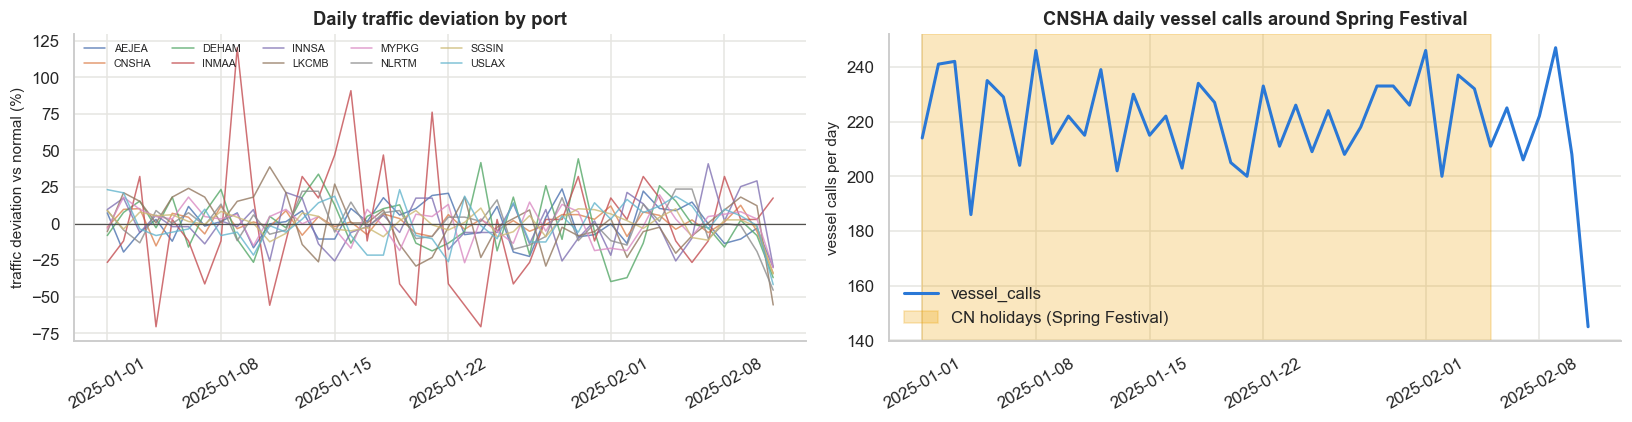

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for p, g in traffic.groupby("port_id"):
    axes[0].plot(g.period_start, g.traffic_deviation_pct, lw=1, alpha=0.8, label=p)
axes[0].axhline(0, color="#52514e", lw=0.8)
axes[0].set_ylabel("traffic deviation vs normal (%)")
axes[0].set_title("Daily traffic deviation by port")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(ncol=5, fontsize=7, loc="upper left")
g = traffic[traffic.port_id == "CNSHA"]
axes[1].plot(g.period_start, g.vessel_calls, color="#2a78d6", label="vessel_calls")
ax2 = axes[1]
hd = hol[hol.country_code == "CN"].holiday_date
axes[1].axvspan(hd.min(), hd.max() + pd.Timedelta("1D"), color="#eda100", alpha=0.25, label="CN holidays (Spring Festival)")
axes[1].set_ylabel("vessel calls per day")
axes[1].set_title("CNSHA daily vessel calls around Spring Festival")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
P.save(fig, "07_traffic")

In [10]:
tr_feats = [c for c in sea.columns if c.startswith(("tr_o_", "tr_d_"))]
tt = stats.screen_numeric(sea, tr_feats)
tt = tt.reindex(tt["cliff_Critical_vs_On-Time"].abs().sort_values(ascending=False).index)
P.save_table(tt, "07_traffic_features_vs_class")
tt[["epsilon_sq", "median_On-Time", "median_At-Risk", "median_Critical", "cliff_Critical_vs_On-Time", "cliff_At-Risk_vs_On-Time", "spearman_rho_delay_h"]].round(3)

,epsilon_sq,median_On-Time,median_At-Risk,median_Critical,cliff_Critical_vs_On-Time,cliff_At-Risk_vs_On-Time,spearman_rho_delay_h
feature,,,,,,,
tr_o_avg_vessel_stay_hours,0.069,24.2,24.8,25.4,0.375,0.251,0.287
tr_d_vessel_calls,0.005,67,66,62,-0.111,-0.056,-0.079
tr_d_container_vessel_calls,0.004,47,46,43,-0.102,-0.047,-0.07
tr_o_traffic_deviation_pct,0.003,1.1,1.3,-2.5,-0.091,-0.005,-0.042
tr_d_import_volume_t,0.003,1.779e+05,1.748e+05,1.665e+05,-0.086,-0.03,-0.049
tr_d_export_volume_t,0.003,1.574e+05,1.554e+05,1.413e+05,-0.082,-0.03,-0.048
tr_d_traffic_deviation_pct,0.002,1.3,1.3,-0.9,-0.067,-0.012,-0.04
tr_d_avg_vessel_stay_hours,0.002,24.4,24.6,24.6,0.063,0.049,0.053
tr_o_import_volume_t,0,1.76e+05,2.069e+05,1.929e+05,-0.033,0.001,-0.013


In [11]:
# Traffic volumes are port-scale quantities; check within origin port
for c in ["tr_o_vessel_calls", "tr_o_traffic_deviation_pct", "tr_o_avg_vessel_stay_hours", "tr_o_import_volume_t"]:
    a = sea[c] - sea.groupby("origin_port_id")[c].transform("mean")
    print(f"{c:30s} pooled ρ={ss.spearmanr(sea[c], sea.actual_delay_hours)[0]:+.3f} | within-origin ρ={ss.spearmanr(a, sea.actual_delay_hours)[0]:+.3f}")

tr_o_vessel_calls              pooled ρ=+0.016 | within-origin ρ=-0.043
tr_o_traffic_deviation_pct     pooled ρ=-0.042 | within-origin ρ=-0.044
tr_o_avg_vessel_stay_hours     pooled ρ=+0.287 | within-origin ρ=+0.217
tr_o_import_volume_t           pooled ρ=-0.013 | within-origin ρ=-0.101


## G4. Public holidays

In [12]:
hd = features._holiday_dates(hol, meta)
print("holiday-days per port (national + matching subdivision):")
print(hd.groupby("port_id").size().reindex(meta.port_id).fillna(0).astype(int).to_dict())
print("calendar covers dates up to:", hol.holiday_date.max().date(), "| latest expected arrival:", sea.expected_arrival_ts.max().date())
print("sea shipments whose expected arrival falls after the calendar's last date:", (~sea.hol_calendar_covers_exp_arr).sum())
print("holiday_period_days vs number of listed dates per holiday:")
print(hol.groupby(["country_code", "holiday_name"]).agg(listed_dates=("holiday_date", "nunique"), holiday_period_days=("holiday_period_days", "first")).query("listed_dates != holiday_period_days"))

holiday-days per port (national + matching subdivision):
{'INMAA': 5, 'INNSA': 3, 'SGSIN': 3, 'CNSHA': 9, 'AEJEA': 1, 'NLRTM': 1, 'USLAX': 3, 'DEHAM': 1, 'LKCMB': 4, 'MYPKG': 4}
calendar covers dates up to: 2025-02-26 | latest expected arrival: 2025-03-12
sea shipments whose expected arrival falls after the calendar's last date: 267
holiday_period_days vs number of listed dates per holiday:
                                       listed_dates  holiday_period_days
country_code holiday_name                                               
IN           Pongal                               1                    3
             Thiruvalluvar Day                    1                    3
             Uzhavar Thirunal                     1                    3
MY           Chinese New Year                     1                    2
             Chinese New Year (Day 2)             1                    2
SG           Chinese New Year                     1                    2
             Chinese N

In [13]:
# Port operations on holidays vs other days (within port, daily means)
loc_day = []
for p, tzname in meta.set_index("port_id").local_timezone.items():
    g = tel[tel.port_id == p].copy()
    g["local_date"] = g.ts_hour.dt.tz_convert(tzname).dt.tz_localize(None).dt.normalize()
    loc_day.append(g)
tl = pd.concat(loc_day).merge(hd.rename(columns={"holiday_date": "local_date"}).assign(holiday=True), on=["port_id", "local_date"], how="left")
tl["holiday"] = tl.holiday.notna()
hol_eff = tl.groupby(["port_id", "holiday"])[["port_utilization_pct", "vessels_at_anchor", "container_dwell_hours"]].mean().unstack()
diff = pd.DataFrame({m: hol_eff[(m, True)] - hol_eff[(m, False)] for m in ["port_utilization_pct", "vessels_at_anchor", "container_dwell_hours"]})
diff["holiday_hours"] = tl[tl.holiday].groupby("port_id").size()
print("Holiday minus non-holiday mean, by port:")
diff.dropna(subset=["holiday_hours"]).round(2)

Holiday minus non-holiday mean, by port:


,port_utilization_pct,vessels_at_anchor,container_dwell_hours,holiday_hours
port_id,,,,
AEJEA,-4.35,-0.32,-1.2,20
CNSHA,-21.83,4.34,18.85,208
DEHAM,-12.66,-0.01,-1.78,23
INMAA,-17.64,0.48,3.07,96
INNSA,-0.68,1.21,8.09,24
LKCMB,-10.67,-0.32,-1.15,72
MYPKG,-10.61,1.09,4.14,88
NLRTM,-14.26,-5.32,-20,23
SGSIN,-9.09,-1.17,-4.43,64


o_hol {'p_value': np.float64(0.0), 'cramers_v': np.float64(0.125)}
d_hol {'p_value': np.float64(0.001), 'cramers_v': np.float64(0.036)}
h_hol {'p_value': np.float64(0.0), 'cramers_v': np.float64(0.134)}


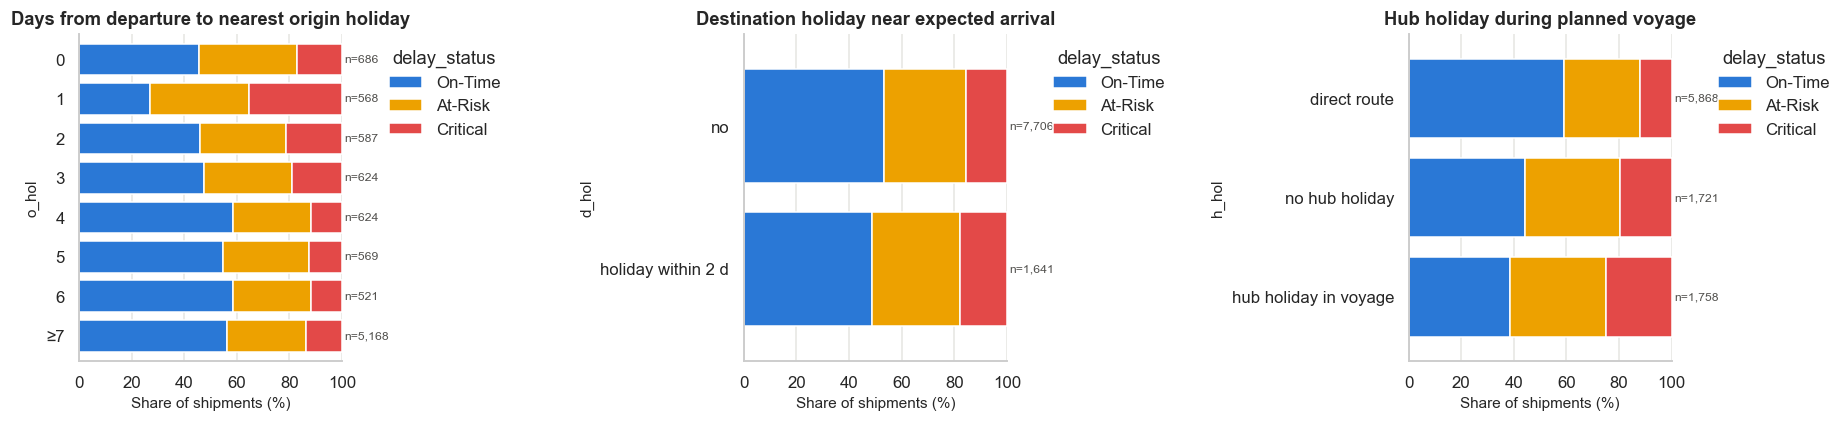

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sea["o_hol"] = sea.hol_o_days_to_nearest.clip(upper=7).map(lambda d: f"{int(d)}" if d < 7 else "≥7")
P.stacked_class_bar(sea, "o_hol", ax=axes[0], order=["0", "1", "2", "3", "4", "5", "6", "≥7"], title="Days from departure to nearest origin holiday")
sea["d_hol"] = np.where(sea.hol_d_within_2d_of_exp_arr == 1, "holiday within 2 d", "no")
P.stacked_class_bar(sea, "d_hol", ax=axes[1], order=["no", "holiday within 2 d"], title="Destination holiday near expected arrival")
sea["h_hol"] = sea.hol_h_days_in_voyage.map(lambda v: "direct route" if pd.isna(v) else ("hub holiday in voyage" if v > 0 else "no hub holiday"))
P.stacked_class_bar(sea, "h_hol", ax=axes[2], order=["direct route", "no hub holiday", "hub holiday in voyage"], title="Hub holiday during planned voyage")
P.save(fig, "07_holidays_by_class")
for c in ["o_hol", "d_hol", "h_hol"]:
    print(c, {k: round(v, 3) for k, v in stats.chi2_vs_target(sea, c).items() if k in ("cramers_v", "p_value")})

In [15]:
# Is the origin-holiday effect driven by one holiday (CN Spring Festival)?
near = sea[sea.hol_o_within_2d == 1]
display(stats.class_rates(near, "origin_port_id").sort_values("n", ascending=False))
not_cn = sea[sea.origin_port_id != "CNSHA"]
print("origin holiday within 2 d, excluding CNSHA origins:", {k: round(v, 3) for k, v in stats.chi2_vs_target(not_cn, "hol_o_within_2d").items() if k in ("cramers_v", "p_value")})
display(stats.class_rates(not_cn, "hol_o_within_2d"))

,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
origin_port_id,,,,,,,
CNSHA,699,33.5,36.3,30.2,66.5,62.9,69.9
SGSIN,296,57.4,33.8,8.8,42.6,37.1,48.3
MYPKG,220,55.5,29.1,15.5,44.5,38.1,51.2
LKCMB,210,38.6,42.9,18.6,61.4,54.7,67.8
USLAX,129,26.4,32.6,41.1,73.6,65.4,80.5
INMAA,128,37.5,39.8,22.7,62.5,53.9,70.4
INNSA,66,25.8,40.9,33.3,74.2,62.6,83.3
NLRTM,38,15.8,28.9,55.3,84.2,69.6,92.6
DEHAM,29,55.2,27.6,17.2,44.8,28.4,62.5


origin holiday within 2 d, excluding CNSHA origins: {'p_value': np.float64(0.0), 'cramers_v': np.float64(0.086)}


,n,pct_On-Time,pct_At-Risk,pct_Critical,pct_delayed(>12h),ci95_low,ci95_high
hol_o_within_2d,,,,,,,
0,6125,55.4,30.5,14.1,44.6,43.4,45.9
1,1142,44.1,35.6,20.3,55.9,53,58.7


## G5. Findings — disruptions, traffic, holidays

**Disruptions**
* 55 events: weather 27 (mostly high severity, median 15 h), equipment failure 11, congestion 9 (median 61 h), strike 7
  (median 56 h), cyber 1. Severity tracks `affected_capacity_pct`. Seven events sit at exactly 85.0 %, consistent with a cap.
* **An origin disruption active at departure is the single strongest signal in the dataset** (Cramér's V = 0.33 for severity):
  no event → 41 % delayed / 10 % Critical; medium → 71 % / 24 %; high → 96 % / 73 %. By type: active **weather** event → 98 % delayed,
  **86 % Critical** (n = 374); strike → 85 % / 40 %; congestion → 77 % / 33 %; equipment failure → 48 % / 11 % (close to baseline).
  Low-severity events (n = 63) show no elevation.
* Among the 1,431 shipments departing during an origin event, the event's **affected capacity %** is strongly associated with delay
  (ρ = +0.60), and **hours already elapsed** negatively (ρ = −0.25): leaving late in an event is less risky. Both are knowable at
  departure. **Remaining duration** (needs `event_end`) is *not* knowable and, interestingly, is less informative (ρ = −0.12).
* **Events that start after departure** (future information) matter too. Among shipments with no origin event at departure,
  those whose origin/destination has an event starting during the voyage are delayed 44 % vs 33 %. A departure-time model cannot
  see this risk, so it is a floor on achievable error unless forecasts or en-route updates are added.
* 15 % of sea shipments depart with an active event at origin, 15 % with one at the destination, 15 % at the hub.

**Port traffic history**
* **`port_traffic_history` is derived from the hourly telemetry.** `vessel_calls` equals the daily sum of telemetry
  `vessel_arrivals` on all 410 complete days, and `avg_vessel_stay_hours` equals the daily mean `vessel_time_in_port_hours`
  (≤ 0.05 h rounding). It contains no independent information about these quantities; volumes (`import_volume_t`,
  `export_volume_t`) scale with vessel calls between ports but not within port.
* The only traffic feature with signal is `tr_o_avg_vessel_stay_hours` (δ Critical vs On-Time = 0.38), which is a lagged duplicate
  of telemetry vessel time. `traffic_deviation_pct` is unrelated to delay (ρ = −0.04) and to telemetry congestion.
  Recommendation: do not add traffic features on top of telemetry features.

**Public holidays**
* Holidays coincide with lower utilization at every port (−4 to −36 pp). At **CNSHA (Spring Festival)** they coincide with a
  +4.3-vessel anchor backlog and +19 h dwell, with no logged disruption event.
* Departing within 2 days of an origin holiday: 60 % vs 44 % delayed (V = 0.14; days-to-holiday bands V = 0.125). This is
  **not only Spring Festival**: excluding CNSHA origins it remains at 56 % vs 45 % (V = 0.086). A **hub holiday during the planned voyage** is associated with higher risk (V = 0.13);
  destination holiday near expected arrival is weak (V = 0.04).
* Holiday features are calendar-based and safe at prediction time. Caveats: the calendar ends 26 Feb while 267 sea shipments
  are expected to arrive later (their destination-holiday features are unknown, not "no holiday"); `port_closed` is only
  populated for CN and is always `False`; multi-day periods are listed as separate dated rows (e.g. Pongal = 3 named days), so
  `holiday_period_days` describes the period, not the row.